In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.6 MB/s eta 0:00:00


In [3]:
import shutil

files = ['fast_kan_conv.py', 'kan_conv.py', 'kan.py', 'layers.py', 'utils.py', '__init__.py']

for f in files:

    shutil.copy(f'/content/drive/MyDrive/GKANSU/{f}', f'/content/{f}')

print("All files copied successfully!")

All files copied successfully!


In [4]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch_geometric.nn as pyg_nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, DataLoader as GeometricDataLoader
from skimage.metrics import mean_squared_error
from fast_kan_conv import FastKANConv2DLayer
from kan_conv import KANConv2DLayer

# Spatial-Spectral Attention Module
class SpatialSpectralAttention(nn.Module):
    def __init__(self, channels):
        super(SpatialSpectralAttention, self).__init__()
        self.conv1x1 = nn.Conv2d(channels, channels // 2, kernel_size=1)
        self.conv3x3 = nn.Conv2d(channels // 2, channels, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv1x1(x)
        attn = self.conv3x3(attn)
        attn = self.sigmoid(attn)
        return x * attn

# Improved Graph-KAN Spectral Upsampling Model with Residual Projection
class GKANSU_Improved(nn.Module):
    def __init__(self, in_channels, out_channels, hidden_dim=128, num_gat_layers=3, img_size=(64, 64)):
        """
        :param in_channels: Number of input spectral bands (e.g., 20)
        :param out_channels: Number of output spectral bands (e.g., 200)
        :param hidden_dim: Hidden dimension for the GAT/KAN layers
        :param num_gat_layers: Number of GAT layers to stack
        :param img_size: (height, width) of each image patch
        """
        super(GKANSU_Improved, self).__init__()
        self.img_size = img_size

        # Add a projection layer to match input channels to hidden_dim
        if in_channels != hidden_dim:
            self.input_proj = nn.Linear(in_channels, hidden_dim)
        else:
            self.input_proj = nn.Identity()

        # Graph-Spectral Feature Extraction using multiple GAT layers
        self.gat_layers = nn.ModuleList()
        self.batch_norms = nn.ModuleList()

        # First GAT layer
        self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
        self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Additional GAT layers
        for _ in range(num_gat_layers - 1):
            self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
            self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Multiple KAN Blocks with Residual Connections
        self.fast_kan1 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.fast_kan2 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)

        # Spatial-Spectral Attention
        self.ssa = SpatialSpectralAttention(hidden_dim)

        # Final KAN-based Refinement
        self.final_refinement = KANConv2DLayer(hidden_dim, out_channels, kernel_size=3, padding=1)

        # Non-negativity constraint (using ReLU only)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index):
        """
        :param x: Node features, shape [num_nodes, in_channels]
        :param edge_index: Graph edges (2, E)
        :return: Super-resolved output, shape [batch, out_channels, H, W]
        """
        # Project input features to hidden_dim
        x = self.input_proj(x)

        # Graph-Spectral Learning with GAT layers with skip connections
        for gat_layer, bn in zip(self.gat_layers, self.batch_norms):
            residual = x
            x = gat_layer(x, edge_index)
            x = bn(x)
            x = F.relu(x + residual)

        # Reshape from (num_nodes, hidden_dim) to (batch, hidden_dim, H, W)
        num_nodes = x.shape[0]
        batch_size = num_nodes // (self.img_size[0] * self.img_size[1])
        x = x.view(batch_size, self.img_size[0], self.img_size[1], -1)
        x = x.permute(0, 3, 1, 2)

        # Multiple KAN Blocks with skip connections
        residual = x
        x = self.fast_kan1(x)
        x = F.relu(x + residual)

        residual = x
        x = self.fast_kan2(x)
        x = F.relu(x + residual)

        # Spatial-Spectral Attention
        x = self.ssa(x)

        # Final KAN-based Refinement
        x = self.final_refinement(x)

        # Apply non-negativity constraint
        x = self.relu(x)

        return x



# Data Prep

In [5]:
# Data PRep
# Data Loading Function
def load_npy_files_from_folder(folder_path):
    npy_files = [f for f in os.listdir(folder_path) if f.endswith('.npy')]
    npy_files.sort()
    arrays = [np.load(os.path.join(folder_path, file)) for file in npy_files]
    return np.stack(arrays, axis=0)

# Paths to LR and HR Data
LR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/low_res_patches'
HR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/high_res_patches'
lr_images = load_npy_files_from_folder(LR_folder_path).astype(np.float32)
hr_images = load_npy_files_from_folder(HR_folder_path).astype(np.float32)

# ----------- NORMALIZATION -----------
# Min-Max Normalization per channel
lr_min = lr_images.min(axis=(0, 1, 2), keepdims=True)
lr_max = lr_images.max(axis=(0, 1, 2), keepdims=True)
hr_min = hr_images.min(axis=(0, 1, 2), keepdims=True)
hr_max = hr_images.max(axis=(0, 1, 2), keepdims=True)
"""
lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)
"""

lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)


# ── ADD AUGMENTATION HERE ──────────────────────────────────────
def augment_hsi(lr, hr):
    augmented_lr, augmented_hr = [lr], [hr]
    augmented_lr.append(np.flip(lr, axis=1).copy())
    augmented_hr.append(np.flip(hr, axis=1).copy())
    augmented_lr.append(np.flip(lr, axis=0).copy())
    augmented_hr.append(np.flip(hr, axis=0).copy())
    augmented_lr.append(np.rot90(lr, k=1).copy())
    augmented_hr.append(np.rot90(hr, k=1).copy())
    augmented_lr.append(np.rot90(lr, k=2).copy())
    augmented_hr.append(np.rot90(hr, k=2).copy())
    return augmented_lr, augmented_hr

aug_lr, aug_hr = [], []
for lr, hr in zip(lr_images, hr_images):
    lrs, hrs = augment_hsi(lr, hr)
    aug_lr.extend(lrs)
    aug_hr.extend(hrs)

lr_images = np.array(aug_lr)
hr_images = np.array(aug_hr)
print(f"After augmentation: {len(lr_images)} samples")  # should print 140
# ──────────────────────────────────────────────────────────────

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)



# Function to Create Graph Data
def create_graph_from_image(image):
    H, W, C = image.shape
    num_nodes = H * W
    features = image.reshape(num_nodes, C)  # Flatten spatial dims

    edge_index = []
    for i in range(H):
        for j in range(W):
            node = i * W + j
            if i > 0: edge_index.append([node, node - W])
            if i < H - 1: edge_index.append([node, node + W])
            if j > 0: edge_index.append([node, node - 1])
            if j < W - 1: edge_index.append([node, node + 1])
    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

    return Data(x=torch.tensor(features, dtype=torch.float), edge_index=edge_index)

# Graph Dataset Class
class HSI_GraphDataset(Dataset):
    def __init__(self, lr_images, hr_images):
        assert len(lr_images) == len(hr_images), "LR and HR images must have the same number of samples"
        self.graphs = [create_graph_from_image(img) for img in lr_images]
        self.hr_images = [torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) for img in hr_images]

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx], self.hr_images[idx]


After augmentation: 180 samples


In [6]:
import torch
print(torch.cuda.is_available())        # Should print True
print(torch.cuda.get_device_name(0))    # Should print T4 or similar

print(torch.cuda.get_device_name(0))  # run this before training

True
Tesla T4
Tesla T4


# Training

/tmp/ipykernel_697/2529718413.py:4: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
/tmp/ipykernel_697/2529718413.py:5: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)


Epoch 1/150, SAM+MSE Loss: 0.6397
Epoch 2/150, SAM+MSE Loss: 0.4593
Epoch 3/150, SAM+MSE Loss: 0.3799
Epoch 4/150, SAM+MSE Loss: 0.3172
Epoch 5/150, SAM+MSE Loss: 0.2816
Epoch 6/150, SAM+MSE Loss: 0.2600
Epoch 7/150, SAM+MSE Loss: 0.2394
Epoch 8/150, SAM+MSE Loss: 0.2206
Epoch 9/150, SAM+MSE Loss: 0.2095
Epoch 10/150, SAM+MSE Loss: 0.2034
Epoch 11/150, SAM+MSE Loss: 0.1935
Epoch 12/150, SAM+MSE Loss: 0.1896
Epoch 13/150, SAM+MSE Loss: 0.1895
Early stopping trigger count: 1/10
Epoch 14/150, SAM+MSE Loss: 0.1833
Epoch 15/150, SAM+MSE Loss: 0.1816
Epoch 16/150, SAM+MSE Loss: 0.1743
Epoch 17/150, SAM+MSE Loss: 0.1694
Epoch 18/150, SAM+MSE Loss: 0.1684
Epoch 19/150, SAM+MSE Loss: 0.1741
Early stopping trigger count: 1/10
Epoch 20/150, SAM+MSE Loss: 0.1771
Early stopping trigger count: 2/10
Epoch 21/150, SAM+MSE Loss: 0.1675
Epoch 22/150, SAM+MSE Loss: 0.1651
Epoch 23/150, SAM+MSE Loss: 0.1564
Epoch 24/150, SAM+MSE Loss: 0.1555
Epoch 25/150, SAM+MSE Loss: 0.1515
Epoch 26/150, SAM+MSE Loss: 0

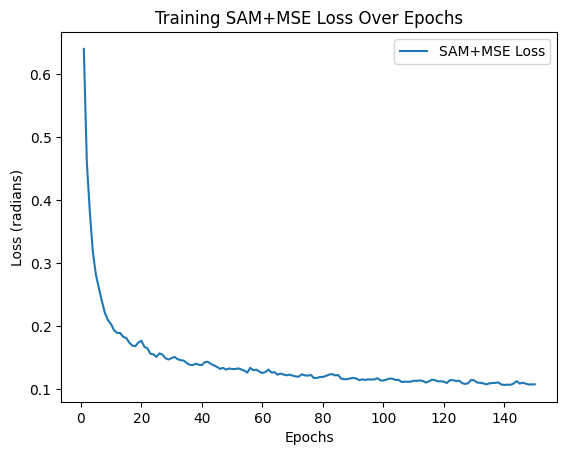

In [7]:
# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)
    angle = torch.acos(cos_angle)
    return torch.mean(angle)

# Combined SAM + MSE Loss
def combined_loss(hr, sr, alpha=0.7, eps=1e-8):
    sam  = sam_loss(hr, sr, eps)
    mse  = F.mse_loss(sr, hr)
    return alpha * sam + (1 - alpha) * mse

# Model Training with Early Stopping and SAM+MSE Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use combined SAM + MSE loss instead of SAM only
criterion = combined_loss

loss_history = []
patience = 10
min_delta = 1e-4
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM+MSE Loss: {avg_loss:.4f}")

    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM+MSE Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM+MSE Loss Over Epochs")
plt.legend()
plt.show()

In [8]:
"""# ============================================================
# INSTALL torch_geometric AND DEPENDENCIES
# ============================================================

!pip install torch_geometric
!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html

print("✅ torch_geometric installed!")

# Import to verify
import torch_geometric
print(f"✅ torch_geometric version: {torch_geometric.__version__}")"""

'# ============================================================\n# INSTALL torch_geometric AND DEPENDENCIES\n# ============================================================\n\n!pip install torch_geometric\n!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html\n\nprint("✅ torch_geometric installed!")\n\n# Import to verify\nimport torch_geometric\nprint(f"✅ torch_geometric version: {torch_geometric.__version__}")'

In [9]:
"""# ── FastKANConv2DLayer inspector ──────────────────────────────
import inspect

layer = model.fast_kan1

# Q1: constructor signature
print("=== CONSTRUCTOR SIGNATURE ===")
print(inspect.signature(layer.__class__.__init__))

# Q2: all parameters and their shapes
print("\n=== ALL NAMED PARAMETERS ===")
for name, param in layer.named_parameters():
    print(f"  {name:40s}  shape={tuple(param.shape)}")

# Q3: all submodules
print("\n=== SUBMODULES ===")
for name, mod in layer.named_modules():
    if name:
        print(f"  {name:40s}  {mod.__class__.__name__}")

# Q4: direct attributes that are tensors
print("\n=== DIRECT TENSOR ATTRIBUTES ===")
for attr in dir(layer):
    if attr.startswith('_'):
        continue
    try:
        val = getattr(layer, attr)
        if isinstance(val, torch.Tensor):
            print(f"  .{attr:38s}  shape={tuple(val.shape)}")
    except:
        pass"""

'# ── FastKANConv2DLayer inspector ──────────────────────────────\nimport inspect\n\nlayer = model.fast_kan1\n\n# Q1: constructor signature\nprint("=== CONSTRUCTOR SIGNATURE ===")\nprint(inspect.signature(layer.__class__.__init__))\n\n# Q2: all parameters and their shapes\nprint("\n=== ALL NAMED PARAMETERS ===")\nfor name, param in layer.named_parameters():\n    print(f"  {name:40s}  shape={tuple(param.shape)}")\n\n# Q3: all submodules\nprint("\n=== SUBMODULES ===")\nfor name, mod in layer.named_modules():\n    if name:\n        print(f"  {name:40s}  {mod.__class__.__name__}")\n\n# Q4: direct attributes that are tensors\nprint("\n=== DIRECT TENSOR ATTRIBUTES ===")\nfor attr in dir(layer):\n    if attr.startswith(\'_\'):\n        continue\n    try:\n        val = getattr(layer, attr)\n        if isinstance(val, torch.Tensor):\n            print(f"  .{attr:38s}  shape={tuple(val.shape)}")\n    except:\n        pass'

In [10]:
"""# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()"""

'# Model Training\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\n\nepochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epoch_loss += loss.item()\n    loss_history.append(epoch_loss / len(train_loader))\n    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")\n\nplt.plot(range(1, epochs + 1), loss_history, label="Training Loss")\nplt.xlabel("Epochs")\nplt.ylabel("Loss")\nplt.title("Training Loss Over Epochs")\nplt

In [11]:
"""# Model Training with Early Stopping
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []
patience = 10         # number of epochs to wait for improvement
min_delta = 1e-4      # minimum change to count as an improvement
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.4f}")

    # Early Stopping Check
    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show() """

'# Model Training with Early Stopping\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\npatience = 10         # number of epochs to wait for improvement\nmin_delta = 1e-4      # minimum change to count as an improvement\nbest_loss = float(\'inf\')\ntrigger_times = 0\n\nepochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epoch_loss += loss.item()\n\n    avg_loss = epoch_loss / len(train_loader)\n    loss_history.append(avg_loss)\n 

ORIGINAL MODEL BASELINE
  Parameters : 5,013,457
  SAM        : 7.4100°
  Sparsity   : 0.00%
FastKAN1:   CoV = 1.2795 → high redundancy → prune 50%
FastKAN2:   CoV = 1.2830 → high redundancy → prune 50%
Calibration done: 18 batches captured
FastKAN1: 128 → 64 (pruning 64)
FastKAN2: 128 → 64 (pruning 64)


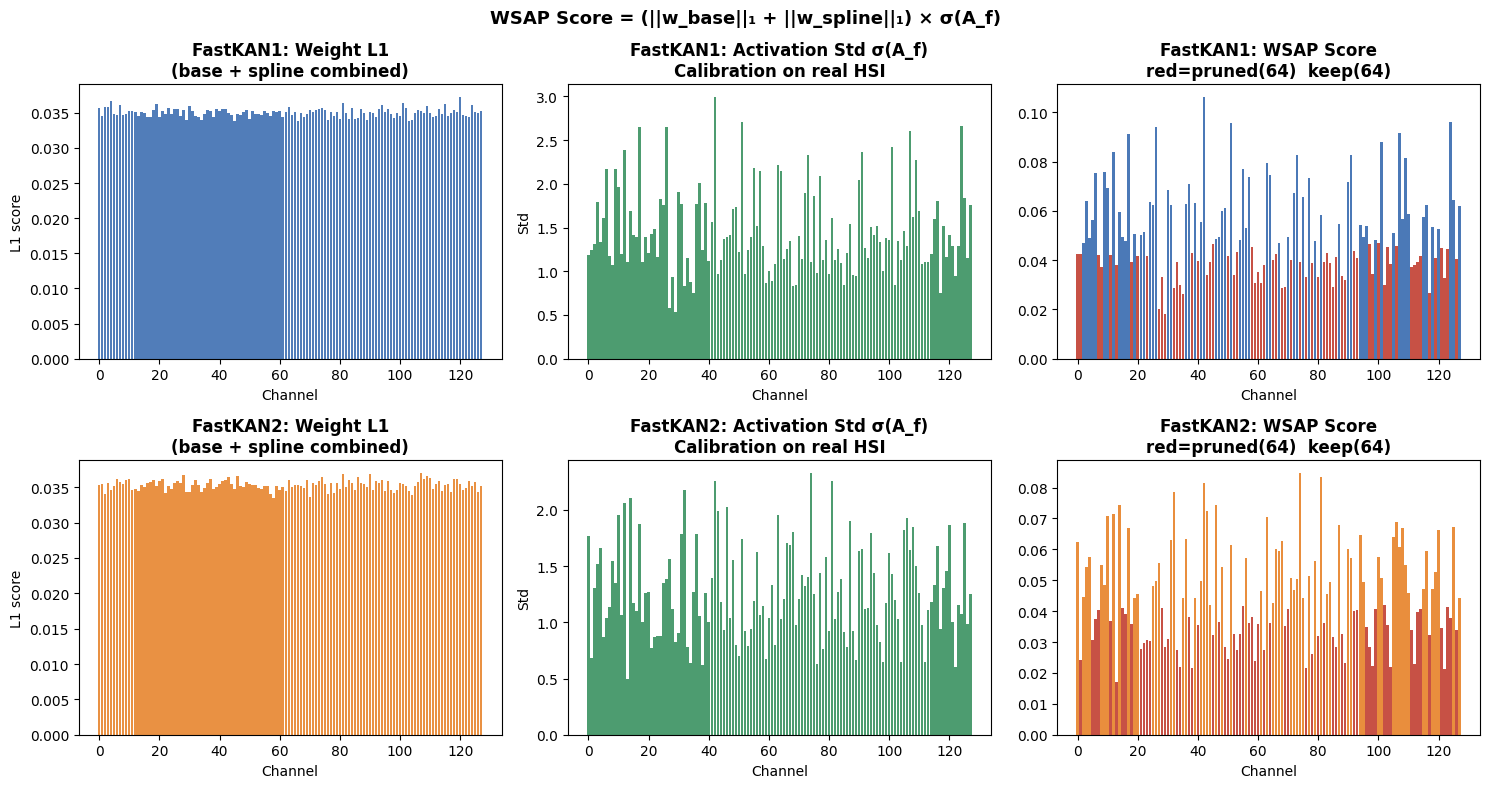

Saved: wsap_score_breakdown.png
Keep indices FK1 (first 10): [2, 3, 4, 5, 6, 9, 10, 12, 14, 15]...
Keep indices FK2 (first 10): [0, 2, 3, 4, 8, 9, 10, 12, 14, 17]...


In [12]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 1 — Load Checkpoint
# ═══════════════════════════════════════════════════════════════
# If 'model' is already in memory from training above, skip this cell.

# ═══════════════════════════════════════════════════════════════
# WSAP CELL 2 — Evaluation Helpers
# ═══════════════════════════════════════════════════════════════
# Uses your existing evaluate() that returns a dict with 'sam' key.

def count_parameters(model):
    total   = sum(p.numel() for p in model.parameters())
    nonzero = sum((p != 0).sum().item() for p in model.parameters())
    return total, nonzero

def calc_sam_pixelwise(outputs, targets):
    all_sam = []
    for out, targ in zip(outputs, targets):
        of = out.permute(0,2,3,1).reshape(-1, out.shape[1])
        tf = targ.permute(0,2,3,1).reshape(-1, targ.shape[1])
        dot = (of * tf).sum(1)
        den = torch.clamp(of.norm(dim=1) * tf.norm(dim=1), min=1e-8)
        all_sam.append(
            torch.rad2deg(torch.acos(torch.clamp(dot/den,-1,1))).mean().item())
    return float(np.mean(all_sam)) if all_sam else float('inf')

def evaluate_wsap(model, loader, device):
    """Returns dict: {'sam': float_degrees, 'sparsity': float%, 'total': int, 'nonzero': int}"""
    model.eval()
    outs, tgts = [], []
    with torch.no_grad():
        for batch in loader:
            if not isinstance(batch, (list, tuple)):
                continue
            g, hr = batch
            sr = model(g.x.to(device), g.edge_index.to(device))
            outs.append(sr)
            tgts.append(hr.to(device))
    total, nz = count_parameters(model)
    return {
        'sam':      calc_sam_pixelwise(outs, tgts),   # degrees
        'sparsity': (1 - nz/total) * 100,
        'total':    total,
        'nonzero':  nz,
    }

# ── Baseline ──────────────────────────────────────────────────
orig_params = sum(p.numel() for p in model.parameters())
baseline    = evaluate_wsap(model, test_loader, device)

print(f'ORIGINAL MODEL BASELINE')
print(f'  Parameters : {orig_params:,}')
print(f'  SAM        : {baseline["sam"]:.4f}°')
print(f'  Sparsity   : {baseline["sparsity"]:.2f}%')
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 3 — Compute WSAP Importance Scores
# ═══════════════════════════════════════════════════════════════
#
# WSAP Formula (adapted for FastKAN):
#   Score(f) = (||base_conv.weight[f]||₁ + ||spline_conv.weight[f]||₁) × σ(A_f)
#
# FastKAN has TWO weight tensors per channel — we include both.
# σ(A_f) = std of channel f's output activations on real training data.

NUM_CALIB_BATCHES = 20
# keep top 70%, prune bottom 30%

def get_layer_prune_ratio(kan_layer):
    w_base   = kan_layer.base_conv[0].weight.data
    w_spline = kan_layer.spline_conv[0].weight.data
    all_weights = torch.cat([w_base.flatten(), w_spline.flatten()])
    cov = all_weights.std() / (all_weights.abs().mean() + 1e-8)
    print(f'  CoV = {cov:.4f}', end=' → ')
    if cov > 0.5:
        print('high redundancy → prune 50%'); return 0.50
    elif cov > 0.2:
        print('medium redundancy → prune 30%'); return 0.30
    else:
        print('low redundancy → prune 10%'); return 0.10



print('FastKAN1:', end=' '); ratio1 = get_layer_prune_ratio(model.fast_kan1)
print('FastKAN2:', end=' '); ratio2 = get_layer_prune_ratio(model.fast_kan2)


calib_acts = {'fast_kan1': [], 'fast_kan2': []}
hooks = []

def make_hook(name):
    def hook_fn(module, input, output):
        calib_acts[name].append(output.detach().cpu())
    return hook_fn

hooks.append(model.fast_kan1.register_forward_hook(make_hook('fast_kan1')))
hooks.append(model.fast_kan2.register_forward_hook(make_hook('fast_kan2')))

model.eval()
with torch.no_grad():
    for i, batch in enumerate(train_loader):
        if i >= NUM_CALIB_BATCHES: break
        if not isinstance(batch, (list, tuple)): continue
        g, _ = batch
        model(g.x.to(device), g.edge_index.to(device))

for h in hooks:
    h.remove()

print(f'Calibration done: {len(calib_acts["fast_kan1"])} batches captured')

def compute_wsap_scores(kan_layer, act_list):
    # base_conv and spline_conv are ModuleLists — access [0] to get the Conv2d
    w_base_l1   = kan_layer.base_conv[0].weight.data.abs().mean(dim=(1,2,3))
    w_spline_l1 = kan_layer.spline_conv[0].weight.data.abs().mean(dim=(1,2,3))
    weight_score = w_base_l1 + w_spline_l1

    all_acts = torch.cat(act_list, dim=0)
    act_std  = all_acts.std(dim=(0, 2, 3)).to(weight_score.device)  # ← .to() fixes it

    wsap_score = weight_score * act_std
    return wsap_score, weight_score, act_std

scores1, w1, a1 = compute_wsap_scores(model.fast_kan1, calib_acts['fast_kan1'])
scores2, w2, a2 = compute_wsap_scores(model.fast_kan2, calib_acts['fast_kan2'])
"""
n_total = model.fast_kan1.out_channels
n_keep  = max(1, int(n_total * KEEP_RATIO))
n_prune = n_total - n_keep
"""


n_total = scores1.shape[0]   # instead of model.fast_kan1.out_channels
n_keep1  = max(1, int(n_total * (1 - ratio1)))
n_keep2  = max(1, int(n_total * (1 - ratio2)))
n_prune1 = n_total - n_keep1
n_prune2 = n_total - n_keep2
print(f'FastKAN1: {n_total} → {n_keep1} (pruning {n_prune1})')
print(f'FastKAN2: {n_total} → {n_keep2} (pruning {n_prune2})')




# ── Score breakdown plots ─────────────────────────────────────
ch = range(n_total)
sorted1 = scores1.argsort(); prune_set1 = set(sorted1[:n_prune1].tolist())
sorted2 = scores2.argsort(); prune_set2 = set(sorted2[:n_prune2].tolist())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (w, a, s, ps, title_prefix, col) in enumerate([
    (w1, a1, scores1, prune_set1, 'FastKAN1', '#3266ad'),
    (w2, a2, scores2, prune_set2, 'FastKAN2', '#e67e22'),
]):
    axes[row,0].bar(ch, w.cpu().numpy(),  color=col,       alpha=0.85)
    axes[row,0].set_title(f'{title_prefix}: Weight L1\n(base + spline combined)', fontweight='bold')
    axes[row,0].set_xlabel('Channel'); axes[row,0].set_ylabel('L1 score')

    axes[row,1].bar(ch, a.cpu().numpy(),  color='seagreen', alpha=0.85)
    axes[row,1].set_title(f'{title_prefix}: Activation Std σ(A_f)\nCalibration on real HSI', fontweight='bold')
    axes[row,1].set_xlabel('Channel'); axes[row,1].set_ylabel('Std')

    colors = ['#c0392b' if i in ps else col for i in ch]
    axes[row,2].bar(ch, s.cpu().numpy(), color=colors, alpha=0.88)
    n_p = n_prune1 if row == 0 else n_prune2
    n_k = n_keep1  if row == 0 else n_keep2
    axes[row,2].set_title(f'{title_prefix}: WSAP Score\nred=pruned({n_p})  keep({n_k})', fontweight='bold')
    axes[row,2].set_xlabel('Channel')


plt.suptitle('WSAP Score = (||w_base||₁ + ||w_spline||₁) × σ(A_f)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/GKANSU/wsap_score_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: wsap_score_breakdown.png')
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 4 — Select Channels to Keep
# ═══════════════════════════════════════════════════════════════

keep_idx1 = torch.topk(scores1, n_keep1).indices.sort().values
keep_idx2 = torch.topk(scores2, n_keep2).indices.sort().values

print(f'Keep indices FK1 (first 10): {keep_idx1[:10].tolist()}...')
print(f'Keep indices FK2 (first 10): {keep_idx2[:10].tolist()}...')





In [13]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 5 — Define PrunedGKANSU Class
# ═══════════════════════════════════════════════════════════════
import copy
class PrunedGKANSU(nn.Module):
    def __init__(self, orig_model, keep_idx1, keep_idx2):
        super().__init__()
        n1 = len(keep_idx1)
        n2 = len(keep_idx2)
        hidden_dim = orig_model.fast_kan1.base_conv[0].weight.shape[1]

        # ── Unchanged layers ─────────────────────────────────
        self.input_proj   = copy.deepcopy(orig_model.input_proj)
        self.gat_layers   = copy.deepcopy(orig_model.gat_layers)
        self.batch_norms  = copy.deepcopy(orig_model.batch_norms)
        self.ssa          = copy.deepcopy(orig_model.ssa)
        self.final_refinement = copy.deepcopy(orig_model.final_refinement)
        self.relu         = orig_model.relu
        self.img_size     = orig_model.img_size

        # ── FastKAN1 pruned ───────────────────────────────────
        self.fast_kan1 = copy.deepcopy(orig_model.fast_kan1)
        self.fast_kan1.base_conv[0].weight.data = \
            orig_model.fast_kan1.base_conv[0].weight.data[keep_idx1]
        self.fast_kan1.spline_conv[0].weight.data = \
            orig_model.fast_kan1.spline_conv[0].weight.data[keep_idx1]

        # ── FastKAN2 pruned ───────────────────────────────────
        G = orig_model.fast_kan2.rbf.grid.shape[0]
        spline_in_idx = torch.cat(
            [keep_idx1 * G + g for g in range(G)]
        ).sort().values

        self.fast_kan2 = copy.deepcopy(orig_model.fast_kan2)
        self.fast_kan2.base_conv[0].weight.data = \
            orig_model.fast_kan2.base_conv[0].weight.data[keep_idx2][:, keep_idx1]
        self.fast_kan2.spline_conv[0].weight.data = \
            orig_model.fast_kan2.spline_conv[0].weight.data[keep_idx2][:, spline_in_idx]

        # ── Residual projections to fix channel mismatch ─────
        self.res_proj1 = nn.Conv2d(hidden_dim, n1, kernel_size=1, bias=False)
        self.res_proj2 = nn.Conv2d(n1, n2,        kernel_size=1, bias=False)
        nn.init.xavier_uniform_(self.res_proj1.weight)
        nn.init.xavier_uniform_(self.res_proj2.weight)

        # ── Projection back to hidden_dim after KAN2 ─────────
        # needed because ssa and final_refinement expect hidden_dim
        self.restore_proj = nn.Conv2d(n2, hidden_dim, kernel_size=1, bias=False)
        nn.init.xavier_uniform_(self.restore_proj.weight)

    def forward(self, x, edge_index):
        x = self.input_proj(x)

        for gat_layer, bn in zip(self.gat_layers, self.batch_norms):
            residual = x
            x = gat_layer(x, edge_index)
            x = bn(x)
            x = F.relu(x + residual)

        num_nodes = x.shape[0]
        batch_size = num_nodes // (self.img_size[0] * self.img_size[1])
        x = x.view(batch_size, self.img_size[0], self.img_size[1], -1)
        x = x.permute(0, 3, 1, 2)

        # FastKAN1 (pruned channels)
        res1 = self.res_proj1(x)
        x    = self.fast_kan1(x)
        x    = F.relu(x + res1)

        # FastKAN2 (pruned channels)
        res2 = self.res_proj2(x)
        x    = self.fast_kan2(x)
        x    = F.relu(x + res2)

        # Restore to hidden_dim for ssa + final_refinement
        # Restore to hidden_dim for ssa + final_refinement
        x = F.relu(self.restore_proj(x))

        x = self.ssa(x)
        x = self.final_refinement(x)
        x = torch.clamp(x, 0, 1)  # ← add this
        return x

In [14]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 6 — Build Pruned Model Instance
# ═══════════════════════════════════════════════════════════════

pruned_model = PrunedGKANSU(model, keep_idx1, keep_idx2).to(device)

pruned_params = sum(p.numel() for p in pruned_model.parameters())
print(f'Original params : {orig_params:,}')
print(f'Pruned params   : {pruned_params:,}')
print(f'Reduction       : {(1 - pruned_params/orig_params)*100:.1f}%')

# Quick forward pass check
for batch in test_loader:
    g, hr = batch
    with torch.no_grad():
        out = pruned_model(g.x.to(device), g.edge_index.to(device))
    print(f'Forward pass OK: {out.shape} ✓')
    break

Original params : 5,013,457
Pruned params   : 3,375,057
Reduction       : 32.7%
Forward pass OK: torch.Size([8, 200, 64, 64]) ✓


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1790: UserWarning: input's size at dim=1 does not match num_features. You can silence this warning by not passing in num_features, which is not used because affine=False
  return forward_call(*args, **kwargs)


In [15]:
# Debug forward pass of pruned model
for batch in test_loader:
    g, hr = batch
    with torch.no_grad():
        out = pruned_model(g.x.to(device), g.edge_index.to(device))
    print(f'Output range: min={out.min():.4f}  max={out.max():.4f}')
    print(f'Output has NaN: {torch.isnan(out).any()}')
    print(f'Output has Inf: {torch.isinf(out).any()}')
    print(f'HR range:    min={hr.min():.4f}  max={hr.max():.4f}')
    break

Output range: min=0.0000  max=1.0000
Output has NaN: False
Output has Inf: False
HR range:    min=0.0000  max=1.0000


In [16]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 7 — Evaluate BEFORE Fine-tuning
# ═══════════════════════════════════════════════════════════════

pre_ft = evaluate_wsap(pruned_model, test_loader, device)

print(f'=== IMMEDIATELY AFTER PRUNING (no fine-tuning) ===')
print(f'SAM  original      : {baseline["sam"]:.4f}°')
print(f'SAM  pruned (no FT): {pre_ft["sam"]:.4f}°  (Δ = {pre_ft["sam"] - baseline["sam"]:+.4f}°)')
print()
print('Large degradation is expected — fine-tuning below will recover it.')


=== IMMEDIATELY AFTER PRUNING (no fine-tuning) ===
SAM  original      : 7.4100°
SAM  pruned (no FT): 46.7408°  (Δ = +39.3308°)

Large degradation is expected — fine-tuning below will recover it.


In [16]:
# ============================================================
# PARAMETER COUNT BREAKDOWN — GKANSU_Improved
# ============================================================
import pandas as pd

def count_params(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable

components = {
    'input_proj':       model.input_proj,
    'gat_layers':       model.gat_layers,
    'batch_norms':      model.batch_norms,
    'fast_kan1':        model.fast_kan1,
    'fast_kan2':        model.fast_kan2,
    'ssa':              model.ssa,
    'final_refinement':  model.final_refinement,
}

rows = []
grand_total = 0
for name, module in components.items():
    total, trainable = count_params(module)
    grand_total += total
    rows.append({
        'Component': name,
        'Total Params': total,
        'Trainable Params': trainable,
        '% of Model': None  # filled in after we know grand_total
    })

# whole-model total (sanity check — should equal grand_total above)
model_total, model_trainable = count_params(model)

for r in rows:
    r['% of Model'] = round(100 * r['Total Params'] / model_total, 2)

df = pd.DataFrame(rows)
df = df.sort_values('Total Params', ascending=False).reset_index(drop=True)

print(df.to_string(index=False))
print(f"\nSum of listed components : {grand_total:,}")
print(f"Model total (all params)  : {model_total:,}")
print(f"Model trainable params    : {model_trainable:,}")

if grand_total != model_total:
    print(f"\n⚠️ Mismatch of {model_total - grand_total:,} params — model has parameters "
          f"outside the listed components (check for missed submodules).")

df.to_csv('gkan_param_breakdown.csv', index=False)
print("\nSaved: gkan_param_breakdown.csv")

In [20]:
print("Model exists:", 'model' in dir())
print(model)
for name in ['input_proj', 'gat_layers', 'batch_norms', 'fast_kan1', 'fast_kan2', 'ssa', 'final_refinement']:
    try:
        m = getattr(model, name)
        p = sum(x.numel() for x in m.parameters())
        print(f"{name}: OK, {p:,} params")
    except Exception as e:
        print(f"{name}: FAILED — {e}")

Model exists: True
GKANSU_Improved(
  (input_proj): Linear(in_features=20, out_features=128, bias=True)
  (gat_layers): ModuleList(
    (0-2): 3 x GATConv(128, 128, heads=4)
  )
  (batch_norms): ModuleList(
    (0-2): 3 x BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (fast_kan1): FastKANConv2DLayer(
    (base_activation): SiLU()
    (base_conv): ModuleList(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    )
    (spline_conv): ModuleList(
      (0): Conv2d(1024, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    )
    (layer_norm): ModuleList(
      (0): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    )
    (rbf): RadialBasisFunction()
  )
  (fast_kan2): FastKANConv2DLayer(
    (base_activation): SiLU()
    (base_conv): ModuleList(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    )
    (spline_

=== PHASE 1: Warm-up (5 epochs, only residual projections) ===
  Warmup ep 5/5  SAM=22.6425°

=== PHASE 2: Full fine-tune (50 epochs, all layers) ===
  Epoch   5/50  Loss: 0.195758  SAM: 10.4852°  (Δ=+3.0752°)
    ✓ Best saved: 10.4852°
  Epoch  10/50  Loss: 0.176434  SAM: 9.2116°  (Δ=+1.8015°)
    ✓ Best saved: 9.2116°
  Epoch  15/50  Loss: 0.163349  SAM: 8.4860°  (Δ=+1.0760°)
    ✓ Best saved: 8.4860°
  Epoch  20/50  Loss: 0.156879  SAM: 8.3615°  (Δ=+0.9514°)
    ✓ Best saved: 8.3615°
  Epoch  25/50  Loss: 0.152034  SAM: 8.0268°  (Δ=+0.6167°)
    ✓ Best saved: 8.0268°
  Epoch  30/50  Loss: 0.147700  SAM: 8.1155°  (Δ=+0.7055°)
  Epoch  35/50  Loss: 0.144796  SAM: 7.6491°  (Δ=+0.2390°)
    ✓ Best saved: 7.6491°
  Epoch  40/50  Loss: 0.145408  SAM: 7.7963°  (Δ=+0.3863°)
  Epoch  45/50  Loss: 0.141410  SAM: 7.4885°  (Δ=+0.0785°)
    ✓ Best saved: 7.4885°
  Epoch  50/50  Loss: 0.141493  SAM: 7.5147°  (Δ=+0.1046°)

════════════════════════════════════════════════════════════
  WSAP FINAL R

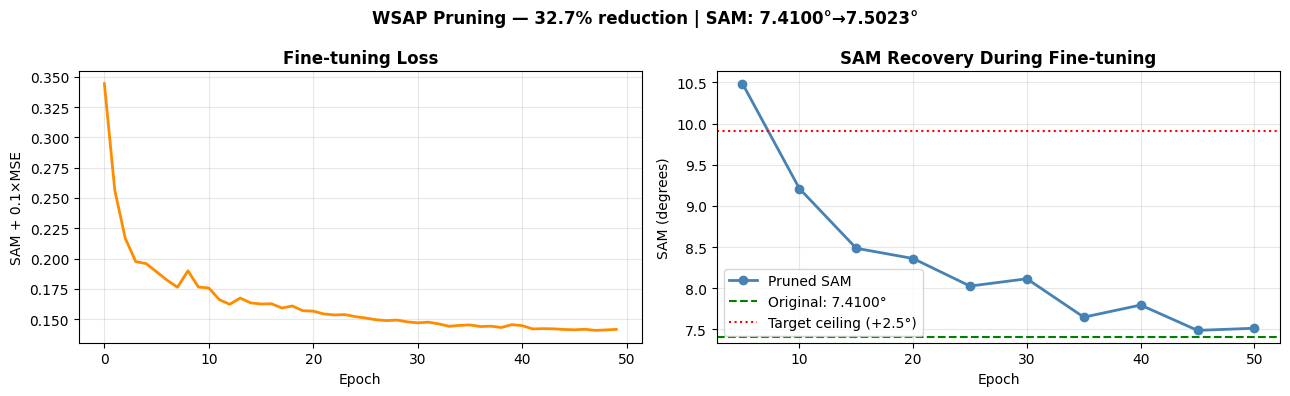

In [17]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 8 — Fine-tune Pruned Model (FIXED)
# ═══════════════════════════════════════════════════════════════

FINETUNE_EPOCHS = 50
FINETUNE_LR     = 1e-4      # was 5e-5 — too slow
PRUNED_SAVE     = '/content/drive/MyDrive/GKANSU/gkan_wsap_pruned.pth'

# ── FIX 3: DO NOT freeze GAT for first 25 epochs ────────────
# Let all layers adapt together first, then optionally freeze
# GAT freezing too early starves the residual projection layers

# All params trainable initially
for param in pruned_model.parameters():
    param.requires_grad = True

# ── FIX 4: Warm-up phase — train only residual projections ───
# res_proj1 and res_proj2 were random-initialized (xavier)
# Give them 5 epochs to align with GAT output before full FT
print("=== PHASE 1: Warm-up (5 epochs, only residual projections) ===")
warmup_params = list(pruned_model.res_proj1.parameters()) + \
                list(pruned_model.res_proj2.parameters())
warmup_opt = optim.Adam(warmup_params, lr=1e-3)

for epoch in range(5):
    pruned_model.train()
    for batch in train_loader:
        if not isinstance(batch, (list, tuple)): continue
        g, hr = batch; hr = hr.to(device)
        warmup_opt.zero_grad()
        sr = pruned_model(g.x.to(device), g.edge_index.to(device))
        loss = sam_loss(hr, sr) + 0.1 * F.mse_loss(sr, hr)
        loss.backward(); warmup_opt.step()
    if (epoch + 1) % 5 == 0:
        r = evaluate_wsap(pruned_model, test_loader, device)
        print(f"  Warmup ep {epoch+1}/5  SAM={r['sam']:.4f}°")

# ── PHASE 2: Full fine-tuning (all layers) ───────────────────
print(f"\n=== PHASE 2: Full fine-tune ({FINETUNE_EPOCHS} epochs, all layers) ===")
ft_optimizer = optim.Adam(pruned_model.parameters(), lr=FINETUNE_LR)
ft_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    ft_optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6
)

best_sam     = float('inf')
ft_loss_hist = []
ft_sam_hist  = []

for epoch in range(FINETUNE_EPOCHS):
    pruned_model.train()
    epoch_loss = 0.0
    for batch in train_loader:
        if not isinstance(batch, (list, tuple)): continue
        g, hr = batch; hr = hr.to(device)
        ft_optimizer.zero_grad()
        sr   = pruned_model(g.x.to(device), g.edge_index.to(device))
        loss = sam_loss(hr, sr) + 0.1 * F.mse_loss(sr, hr)
        loss.backward()
        ft_optimizer.step()
        epoch_loss += loss.item()
    ft_scheduler.step()

    avg_loss = epoch_loss / len(train_loader)
    ft_loss_hist.append(avg_loss)

    # Evaluate every 5 epochs
    if (epoch + 1) % 5 == 0:
        result = evaluate_wsap(pruned_model, test_loader, device)
        ft_sam_hist.append(result['sam'])
        delta = result['sam'] - baseline['sam']
        print(f"  Epoch {epoch+1:3d}/{FINETUNE_EPOCHS}"
              f"  Loss: {avg_loss:.6f}"
              f"  SAM: {result['sam']:.4f}°  (Δ={delta:+.4f}°)")
        if result['sam'] < best_sam:
            best_sam = result['sam']
            torch.save(pruned_model.state_dict(), PRUNED_SAVE)
            print(f"    ✓ Best saved: {best_sam:.4f}°")

# ── FIX 1: Evaluate AFTER fine-tuning, from best checkpoint ──
pruned_model.load_state_dict(torch.load(PRUNED_SAVE, map_location=device))
for param in pruned_model.parameters():
    param.requires_grad = True

# THIS is the correct final evaluation
final = evaluate_wsap(pruned_model, test_loader, device)

print(f'\n{"═"*60}')
print(f'  WSAP FINAL RESULTS — GKANSU_Improved on HSI')
print(f'{"═"*60}')
print(f'  {"Metric":<22} {"Original":>10} {"Pruned+FT":>12} {"Delta":>10}')
print(f'  {"─"*56}')
print(f'  {"Parameters":<22} {orig_params:>10,} {pruned_params:>12,} {(pruned_params-orig_params)/orig_params*100:>+9.1f}%')
print(f'  {"SAM (degrees)":<22} {baseline["sam"]:>10.4f} {final["sam"]:>12.4f} {final["sam"]-baseline["sam"]:>+10.4f}°')
print(f'{"═"*60}')
print(f'  Param reduction : {(1-pruned_params/orig_params)*100:.1f}%')
print(f'  SAM change      : {final["sam"]-baseline["sam"]:+.4f}° (target: < +2.5°)')
print(f'{"═"*60}')

# ── Plot loss curve + SAM recovery ───────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(ft_loss_hist, color='darkorange', lw=2)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('SAM + 0.1×MSE')
ax1.set_title('Fine-tuning Loss', fontweight='bold')
ax1.grid(True, alpha=0.3)

epochs_eval = [5*(i+1) for i in range(len(ft_sam_hist))]
ax2.plot(epochs_eval, ft_sam_hist, color='steelblue',
         marker='o', ms=6, lw=2, label='Pruned SAM')
ax2.axhline(y=baseline['sam'], color='green', ls='--',
            lw=1.5, label=f'Original: {baseline["sam"]:.4f}°')
ax2.axhline(y=baseline['sam']+2.5, color='red', ls=':',
            lw=1.5, label='Target ceiling (+2.5°)')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('SAM (degrees)')
ax2.set_title('SAM Recovery During Fine-tuning', fontweight='bold')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle(f'WSAP Pruning — {(1-pruned_params/orig_params)*100:.1f}% reduction | '
             f'SAM: {baseline["sam"]:.4f}°→{final["sam"]:.4f}°',
             fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/GKANSU/wsap_final_results.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# ═══════════════════════════════════════════════════════════════
# WSAP CELL 9 — Final Results Table
# ═══════════════════════════════════════════════════════════════

final = evaluate_wsap(pruned_model, test_loader, device)


print('=' * 62)
print('    WSAP PRUNING RESULTS — GKANSU_Improved on HSI')
print('=' * 62)
print(f'  {"Metric":<20} {"Original":>10} {"PrunedNoFT":>11} {"Pruned+FT":>10}')
print('-' * 62)
print(f'  {"Parameters":<20} {orig_params:>10,} {pruned_params:>11,} {pruned_params:>10,}')
print(f'  {"Reduction":<20} {"—":>10} {(1-pruned_params/orig_params)*100:>10.1f}% {(1-pruned_params/orig_params)*100:>9.1f}%')
print(f'  {"SAM (degrees)":<20} {baseline["sam"]:>10.4f} {pre_ft["sam"]:>11.4f} {final["sam"]:>10.4f}')
print(f'  {"SAM delta":<20} {"—":>10} {pre_ft["sam"]-baseline["sam"]:>+11.4f} {final["sam"]-baseline["sam"]:>+10.4f}')
print('=' * 62)
print(f'  Param reduction : {(1-pruned_params/orig_params)*100:.1f}%')
print(f'  Final SAM delta : {final["sam"]-baseline["sam"]:+.4f}°  ({(final["sam"]-baseline["sam"])/baseline["sam"]*100:+.2f}%)')
print(f'  WSAP formula    : (||w_base||₁ + ||w_spline||₁) × σ(A_f)')
print(f'  Prune ratio FK1 : {(1 - n_keep1/n_total)*100:.0f}%  FK2: {(1 - n_keep2/n_total)*100:.0f}%')
print('=' * 62)
flag = "✅" if abs(final["sam"] - baseline["sam"]) < 1 else ("⚠️" if abs(final["sam"] - baseline["sam"]) < 3 else "❌")
print(f'\n  Result: {flag}')


    WSAP PRUNING RESULTS — GKANSU_Improved on HSI
  Metric                 Original  PrunedNoFT  Pruned+FT
--------------------------------------------------------------
  Parameters            5,013,457   3,375,057  3,375,057
  Reduction                     —       32.7%      32.7%
  SAM (degrees)            7.4100     46.7408     7.4632
  SAM delta                     —    +39.3308    +0.0532
  Param reduction : 32.7%
  Final SAM delta : +0.0532°  (+0.72%)
  WSAP formula    : (||w_base||₁ + ||w_spline||₁) × σ(A_f)
  Prune ratio FK1 : 50%  FK2: 50%

  Result: ✅


In [19]:
# Check total params in model
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

# Check fast_kan1 and fast_kan2 specifically
for name in ['fast_kan1', 'fast_kan2']:
    layer = getattr(model, name)
    params = sum(p.numel() for p in layer.parameters())
    print(f"{name} params: {params:,}")

# Check output channel activity (no pruning applied yet)
model.eval()
with torch.no_grad():
    out1 = model.fast_kan1(calib_graph.x)
    print(f"\nfast_kan1 output shape: {out1.shape}")
    print(f"fast_kan1 active channels: {(out1.abs().mean(dim=0) > 1e-6).sum().item()} / {out1.shape[1]}")

Total parameters: 5,013,457
fast_kan1 params: 1,327,112
fast_kan2 params: 1,327,112


NameError: name 'calib_graph' is not defined

In [ ]:
# Param counts
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

for name in ['fast_kan1', 'fast_kan2']:
    layer = getattr(model, name)
    params = sum(p.numel() for p in layer.parameters())
    print(f"{name} params: {params:,}")

In [ ]:
import copy
keep1 = keep_mask_from_sv(sv_kan1, 0.90, HIDDEN_DIM)  # 90% pruning
keep2 = keep_mask_from_sv(sv_kan2, 0.90, HIDDEN_DIM)

test_model = copy.deepcopy(model).to(device)

# WITH hooks
h1 = apply_permanent_hook(test_model, 'fast_kan1', keep1)
h2 = apply_permanent_hook(test_model, 'fast_kan2', keep2)
m_with_hooks = evaluate_model_full(test_model, test_loader, device)
print(f"SAM with hooks active:   {m_with_hooks['SAM']:.4f}")

# AFTER removing hooks
h1.remove()
h2.remove()
m_no_hooks = evaluate_model_full(test_model, test_loader, device)
print(f"SAM after hook removal:  {m_no_hooks['SAM']:.4f}")

# If these two numbers are very different → confirms the bug

In [ ]:
"""import os

# Check common locations
paths = [
    '/content/drive/MyDrive/GKANSU/',
    '/content/drive/MyDrive/',
    '/content/',
]

for folder in paths:
    if os.path.exists(folder):
        files = os.listdir(folder)
        pth_files = [f for f in files if f.endswith('.pth')]
        if pth_files:
            print(f"Found in {folder}:")
            for f in pth_files:
                print(f"  {f}")
        else:
            print(f"{folder} — no .pth files found")
    else:
        print(f"{folder} — folder does not exist") """

# Visulization

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error

def spectral_angle_mapper(img1, img2):
    """
    Compute the Spectral Angle Mapper (SAM) between two images.
    img1 and img2 should have shape (H, W, C) where C is the number of spectral bands.
    """
    img1_flat = img1.reshape(-1, img1.shape[-1])
    img2_flat = img2.reshape(-1, img2.shape[-1])

    # Normalize to unit vectors
    norm_img1 = np.linalg.norm(img1_flat, axis=1, keepdims=True)
    norm_img2 = np.linalg.norm(img2_flat, axis=1, keepdims=True)

    dot_product = np.sum(img1_flat * img2_flat, axis=1, keepdims=True)
    sam_values = np.arccos(np.clip(dot_product / (norm_img1 * norm_img2 + 1e-8), -1, 1))

    return np.mean(sam_values)  # Return the average SAM value over all pixels

def test_and_visualize(model, test_loader, device='cpu'):
    model.eval()
    sam_values, rmse_values = [], []

    with torch.no_grad():
        for graph_data, hr_img in test_loader:
            graph_data, hr_img = graph_data.to(device), hr_img.to(device)

            # Extract node features and edge index from graph_data
            sr_img = model(graph_data.x, graph_data.edge_index)  # Corrected model input

            # Reshape SR Image to (Batch, Channels, Height, Width)
            sr_img = sr_img.view(hr_img.shape)

            # Move tensors to CPU for visualization
            sr_img_np = sr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
            hr_img_np = hr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)

            # Calculate RMSE and SAM
            rmse_value = np.sqrt(mean_squared_error(hr_img_np, sr_img_np))
            sam_value = spectral_angle_mapper(hr_img_np, sr_img_np)

            rmse_values.append(rmse_value)
            sam_values.append(sam_value)

            # Plot images
            fig, axs = plt.subplots(1, 2, figsize=(10, 5))
            %) are correctly sitting at the tail end where values are near zero. That validates the Shapley ranking is meaningful.

The metric plots confirm the story — blue (with finetune) stays flat and low across all ratios, well below axs[0].imshow(sr_img_np[:, :, 127], cmap='viridis')
            axs[0].set_title(f"Super-Resolved (SR)\nRMSE: {rmse_value:.4f}, SAM: {sam_value:.4f}")
            axs[0].axis('off')

            axs[1].imshow(hr_img_np[:, :, 127], cmap='viridis')
            axs[1].set_title("High Resolution (HR)")
            axs[1].axis('off')

            plt.show()
            break  # Display only first batch

    print(f"Average RMSE: {sum(rmse_values) / len(rmse_values):.4f}")
    print(f"Average SAM: {sum(sam_values) / len(sam_values):.4f}")

# Test and visualize results
test_and_visualize(model, test_loader, device)

In [ ]:
import requests, os

os.makedirs('datasets', exist_ok=True)

# These are the actual direct file URLs from EHU wiki
# Sometimes they work even when the main page is down
urls = {
    'datasets/Indian_pines_corrected.mat': 'http://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat',
    'datasets/Indian_pines_gt.mat':        'http://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat',
}

for path, url in urls.items():
    print(f'Trying {url}...')
    try:
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            with open(path, 'wb') as f:
                f.write(r.content)
            print(f'  OK — {len(r.content)/1024:.0f} KB saved')
        else:
            print(f'  Failed: status {r.status_code}')
    except Exception as e:
        print(f'  Error: {e}')